# Modelo predictivo avanzado – Precio de Airbnb en Nueva York (2019)

**Objetivo:** predecir el precio por noche (`price`) de un alojamiento de Airbnb en Nueva York a partir de los datos preparados en el notebook anterior (`Airbnb_NYC_2019_limpio.csv`). Es un problema de **regresión**.

*Tiempo total de ejecución en Colab: unos 30 minutos (la sección 8 es la más larga).*

**Contenido**
1. Librerías y carga de datos
2. Ingeniería de características (a)
3. División 70 % / 30 %
4. Balanceo (b)
5. Modelos: 4 métodos de aprendizaje supervisado y 3 métodos de ensamble (d, e)
6. Validación cruzada con el 70 % y medidas de calidad (c, f)
7. Selección de los 3 mejores modelos con ANOVA y Tukey (g)
8. Hiperparametrización: GridSearch y optimización bayesiana (h)
9. Evaluación del modelo final con el 30 % de prueba
10. Pipeline final para despliegue (i)
11. Descarga del modelo final

El despliegue con Streamlit (j) está en el notebook **Despliegue_Airbnb_NYC**.

# 1. Librerías y carga de datos

In [ ]:
!pip install optuna

In [1]:
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, median_absolute_error,
                             mean_absolute_percentage_error, max_error)

# Métodos de aprendizaje supervisado
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor

# Métodos de ensamble
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

# Pruebas estadísticas y optimización bayesiana
from scipy.stats import f_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import optuna

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [2]:
# Antes de ejecutar, subir el archivo Airbnb_NYC_2019_limpio.csv al panel de archivos de Colab
data = pd.read_csv('Airbnb_NYC_2019_limpio.csv')
print(data.shape)
data.head()

(48870, 10)


,neighbourhood_group,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Manhattan,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Manhattan,40.80902,-73.94190,Private room,150,3,0,0.00,1,365
3,Brooklyn,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Manhattan,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 48870 entries, 0 to 48869
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             48870 non-null  str    
 1   latitude                        48870 non-null  float64
 2   longitude                       48870 non-null  float64
 3   room_type                       48870 non-null  str    
 4   price                           48870 non-null  int64  
 5   minimum_nights                  48870 non-null  int64  
 6   number_of_reviews               48870 non-null  int64  
 7   reviews_per_month               48870 non-null  float64
 8   calculated_host_listings_count  48870 non-null  int64  
 9   availability_365                48870 non-null  int64  
dtypes: float64(3), int64(5), str(2)
memory usage: 4.7 MB


# 2. Ingeniería de características (a)

Las operaciones de ingeniería de características son:

| Operación | Variables | Justificación |
|---|---|---|
| **Construcción**: distancia a Times Square (`dist_centro_km`) con la fórmula de *haversine* | `latitude`, `longitude` | La latitud tenía una correlación lineal baja con el precio (0.03) porque su efecto no es lineal: depende de la combinación con la longitud. La distancia al centro resume esa información en una variable con relación clara con el precio. Se conservan también las coordenadas, que los modelos de árboles aprovechan para identificar zonas. |
| **Transformación logarítmica** `log(1 + x)` | `minimum_nights`, `number_of_reviews`, `reviews_per_month`, `calculated_host_listings_count` | Son conteos muy sesgados a la derecha; el logaritmo reduce el peso de los valores extremos en los modelos lineales, KNN y redes neuronales. |
| **Transformación logarítmica de la variable objetivo** `log(1 + price)` | `price` | El precio es muy asimétrico (mediana ≈ 106 USD, máximo 10 000 USD). En la preparación se decidió conservar los precios altos por ser reales; modelar el logaritmo evita que esos casos dominen el entrenamiento. Las predicciones se devuelven a dólares con la transformación inversa. |
| **Codificación one-hot** | `neighbourhood_group`, `room_type` | Los modelos necesitan variables numéricas; las categorías no tienen orden. |
| **Estandarización** (media 0, desviación 1) | Variables numéricas | KNN, la red neuronal y la regresión Ridge son sensibles a la escala de las variables. |

Para poder reutilizar estas operaciones en el despliegue, se escriben como funciones en el archivo `features.py`:

* **`preparar_datos`**: repite las operaciones del notebook de preparación (selección de variables, `reviews_per_month` vacío → 0 y reglas de calidad de `minimum_nights` y `availability_365`). En los datos de entrenamiento no cambia nada, porque ya están limpios; sirve para que los datos nuevos reciban la misma preparación en el despliegue.
* **`crear_variables`**: crea `dist_centro_km` y aplica el logaritmo a los conteos.

Estas funciones se incluyen en el pipeline con `FunctionTransformer`, y así el modelo final se puede usar directamente en la aplicación de Streamlit.

In [4]:
%%writefile features.py
# Funciones de preparación de datos e ingeniería de características.
# Este archivo lo usan el notebook de modelado y la aplicación de Streamlit.
import numpy as np

# Variables que usa el modelo
COLUMNAS_MODELO = ['neighbourhood_group', 'latitude', 'longitude', 'room_type',
                   'minimum_nights', 'number_of_reviews', 'reviews_per_month',
                   'calculated_host_listings_count', 'availability_365']

# Variables de conteo con distribución muy sesgada
COLUMNAS_SESGADAS = ['minimum_nights', 'number_of_reviews', 'reviews_per_month',
                     'calculated_host_listings_count']


def distancia_centro_km(lat, lon):
    # Distancia en km hasta Times Square (fórmula de haversine)
    lat1, lon1 = np.radians(lat), np.radians(lon)
    lat2, lon2 = np.radians(40.7580), np.radians(-73.9855)
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


def preparar_datos(df):
    # Mismas operaciones del notebook de preparación de datos
    df = df[COLUMNAS_MODELO].copy()                                # selección de variables
    df['reviews_per_month'] = df['reviews_per_month'].fillna(0)    # nulos: sin reseñas -> 0
    df['minimum_nights'] = df['minimum_nights'].clip(1, 365)       # regla de calidad
    df['availability_365'] = df['availability_365'].clip(0, 365)   # regla de calidad
    return df


def crear_variables(df):
    # Ingeniería de características
    df = df.copy()
    df['dist_centro_km'] = distancia_centro_km(df['latitude'], df['longitude'])
    for col in COLUMNAS_SESGADAS:
        df[col] = np.log1p(df[col])
    return df

Writing features.py


In [5]:
from features import preparar_datos, crear_variables

# Comprobación de la nueva variable
datos_nuevos = crear_variables(preparar_datos(data))
print('Correlación de Spearman con el precio:')
print(datos_nuevos[['dist_centro_km', 'latitude', 'longitude']].corrwith(data['price'], method='spearman').round(3))

Correlación de Spearman con el precio:
dist_centro_km   -0.457
latitude          0.136
longitude        -0.438
dtype: float64


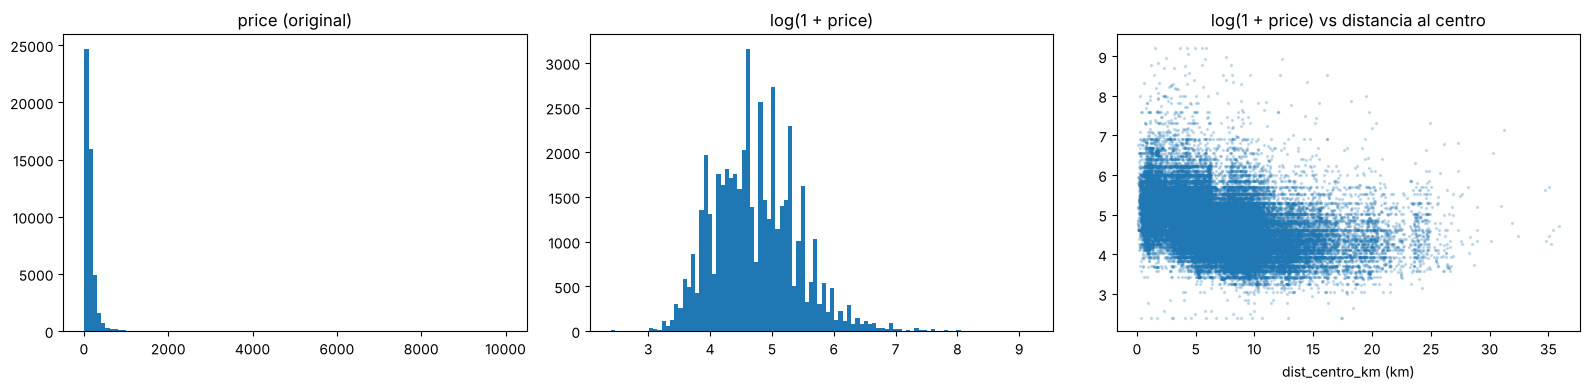

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(data['price'], bins=100)
ax[0].set_title('price (original)')
ax[1].hist(np.log1p(data['price']), bins=100)
ax[1].set_title('log(1 + price)')
ax[2].scatter(datos_nuevos['dist_centro_km'], np.log1p(data['price']), s=2, alpha=0.2)
ax[2].set_title('log(1 + price) vs distancia al centro')
ax[2].set_xlabel('dist_centro_km (km)')
plt.tight_layout()
plt.show()

La variable `dist_centro_km` tiene una correlación de Spearman de aproximadamente **−0.46** con el precio, mucho mayor en valor absoluto que la latitud o la longitud por separado: cuanto más lejos de Times Square, más barato el alojamiento. El histograma muestra que el logaritmo convierte el precio, muy asimétrico, en una distribución aproximadamente simétrica.

In [7]:
# Variables predictoras (X) y variable objetivo (y)
X = data.drop(columns='price')
y = data['price']

numericas = ['latitude', 'longitude', 'dist_centro_km', 'minimum_nights', 'number_of_reviews',
             'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
categoricas = ['neighbourhood_group', 'room_type']


def crear_pipeline(modelo):
    # Escalado de las numéricas y one-hot de las categóricas
    preprocesamiento = ColumnTransformer([
        ('num', StandardScaler(), numericas),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categoricas),
    ], verbose_feature_names_out=False)

    pipe = Pipeline([
        ('preparacion', FunctionTransformer(preparar_datos)),
        ('ingenieria', FunctionTransformer(crear_variables)),
        ('preprocesamiento', preprocesamiento),
        ('modelo', modelo),
    ])
    # El modelo aprende log(1 + price) y devuelve la predicción en dólares
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

El escalado y la codificación están **dentro** del pipeline, de modo que en cada pliegue de la validación cruzada se ajustan solo con los datos de entrenamiento de ese pliegue. Así se evita la fuga de información hacia los datos de validación.

# 3. División de los datos: 70 % entrenamiento y 30 % prueba

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)
print('Entrenamiento (70 %):', X_train.shape)
print('Prueba (30 %):', X_test.shape)

Entrenamiento (70 %): (34209, 9)
Prueba (30 %): (14661, 9)


El 30 % de prueba no se usa en ningún paso de entrenamiento ni de selección; se reserva para la evaluación final del modelo.

# 4. Balanceo (b)

El balanceo (submuestreo, sobremuestreo, SMOTE, etc.) se aplica en problemas de **clasificación** cuando una clase de la variable objetivo tiene muchos menos registros que otra. En este caso la variable objetivo, `price`, es **numérica continua** (regresión), por lo que no existen clases que balancear y **el balanceo no es necesario**.

El problema equivalente en regresión es la asimetría de la variable objetivo (muchos precios bajos y pocos muy altos), y ya se trató con la transformación logarítmica de la sección 2. La distribución de `log(1 + price)` en el conjunto de entrenamiento es aproximadamente simétrica:

In [9]:
print('Asimetría de price:', round(y_train.skew(), 2))
print('Asimetría de log(1 + price):', round(np.log1p(y_train).skew(), 2))

Asimetría de price: 18.09
Asimetría de log(1 + price): 0.61


# 5. Modelos (d, e)

**4 métodos de aprendizaje supervisado**
1. **Regresión Ridge**: regresión lineal con regularización L2.
2. **K vecinos más cercanos (KNN)**: predice el promedio del precio de los alojamientos más parecidos.
3. **Árbol de decisión**: divide los datos con reglas del tipo "si distrito = Manhattan y tipo = casa entera…".
4. **Red neuronal (perceptrón multicapa, MLP)**.

**3 métodos de ensamble**
5. **Random Forest** (*bagging*): promedio de muchos árboles entrenados con muestras distintas.
6. **Gradient Boosting**: árboles secuenciales en los que cada uno corrige los errores del anterior.
7. **XGBoost**: implementación optimizada y regularizada de *gradient boosting*.

In [10]:
modelos = {
    'Ridge': Ridge(alpha=1.0),
    'KNN': KNeighborsRegressor(n_neighbors=15),
    'Árbol de decisión': DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=42),
    'Red neuronal (MLP)': MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=300, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'XGBoost': XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, n_jobs=-1, random_state=42),
}

# 6. Validación cruzada con el 70 % y medidas de calidad (c, f)

Se aplica **validación cruzada de 10 pliegues** (*K-Fold*) sobre el 70 % de entrenamiento. Para cada modelo y cada pliegue se calculan 8 medidas de calidad:

| Medida | Qué mide | Mejor si |
|---|---|---|
| **R² (escala log)** | Proporción de la variabilidad de `log(price)` que explica el modelo. Es la escala en la que el modelo aprende. | Más alta (máx. 1) |
| **R² (USD)** | Proporción de la variabilidad del precio en dólares que explica el modelo. Muy afectada por los precios extremos. | Más alta |
| **MSE** | Error cuadrático medio, en dólares². Penaliza mucho los errores grandes. | Más bajo |
| **MAE** | Error absoluto medio, en dólares. | Más bajo |
| **RMSE** | Raíz del error cuadrático medio, en dólares. Penaliza mucho los errores grandes. | Más bajo |
| **MedAE** | Mediana del error absoluto, en dólares: el error de un alojamiento "típico". | Más bajo |
| **MAPE** | Error porcentual absoluto medio (proporción: 0.30 = 30 %). | Más bajo |
| **Error máximo** | Mayor error absoluto cometido en un solo alojamiento, en dólares. | Más bajo |

In [11]:
def calcular_medidas(y_real, y_pred):
    medidas = {}
    medidas['R2_log'] = r2_score(np.log1p(y_real), np.log1p(y_pred))
    medidas['R2_USD'] = r2_score(y_real, y_pred)
    medidas['MSE'] = mean_squared_error(y_real, y_pred)
    medidas['RMSE'] = np.sqrt(mean_squared_error(y_real, y_pred))
    medidas['MAE'] = mean_absolute_error(y_real, y_pred)
    medidas['MedAE'] = median_absolute_error(y_real, y_pred)
    medidas['MAPE'] = mean_absolute_percentage_error(y_real, y_pred)
    medidas['Error_max'] = max_error(y_real, y_pred)
    return medidas


# Validación cruzada de 10 pliegues sobre el 70 % de entrenamiento
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
resultados = []

for nombre, modelo in modelos.items():
    inicio = time.time()
    pliegue = 1
    for indices_ent, indices_val in kfold.split(X_train):
        X_ent, X_val = X_train.iloc[indices_ent], X_train.iloc[indices_val]
        y_ent, y_val = y_train.iloc[indices_ent], y_train.iloc[indices_val]

        pipe = crear_pipeline(modelo)
        pipe.fit(X_ent, y_ent)
        medidas = calcular_medidas(y_val, pipe.predict(X_val))
        medidas['modelo'] = nombre
        medidas['pliegue'] = pliegue
        resultados.append(medidas)
        pliegue = pliegue + 1
    print(nombre, '- tiempo de aprendizaje (10 pliegues):', round(time.time() - inicio, 1), 's')

resultados_cv = pd.DataFrame(resultados)

Ridge - tiempo de aprendizaje (10 pliegues): 1.0 s


KNN - tiempo de aprendizaje (10 pliegues): 3.1 s


Árbol de decisión - tiempo de aprendizaje (10 pliegues): 2.1 s


Red neuronal (MLP) - tiempo de aprendizaje (10 pliegues): 42.2 s


Random Forest - tiempo de aprendizaje (10 pliegues): 61.8 s


Gradient Boosting - tiempo de aprendizaje (10 pliegues): 51.8 s


XGBoost - tiempo de aprendizaje (10 pliegues): 7.3 s


In [12]:
# Promedio de las medidas en los 10 pliegues, ordenado por MAE
resumen = resultados_cv.drop(columns='pliegue').groupby('modelo').mean().sort_values('MAE')
resumen.round(3)

,R2_log,R2_USD,MSE,RMSE,MAE,MedAE,MAPE,Error_max
modelo,,,,,,,,
XGBoost,0.610,0.200,43266.105,202.309,55.945,23.828,0.319,6234.408
Random Forest,0.602,0.186,44096.840,204.184,56.321,24.228,0.322,6304.367
Gradient Boosting,0.583,0.151,45776.075,208.379,58.125,25.089,0.330,6364.869
KNN,0.566,0.154,45601.405,207.943,58.573,25.241,0.338,6402.511
Red neuronal (MLP),0.574,0.150,45756.987,208.400,58.694,25.136,0.334,6374.149
Árbol de decisión,0.556,0.153,45625.715,208.017,59.623,25.506,0.346,6379.506
Ridge,0.526,0.124,46984.525,211.364,61.063,27.483,0.355,6414.442


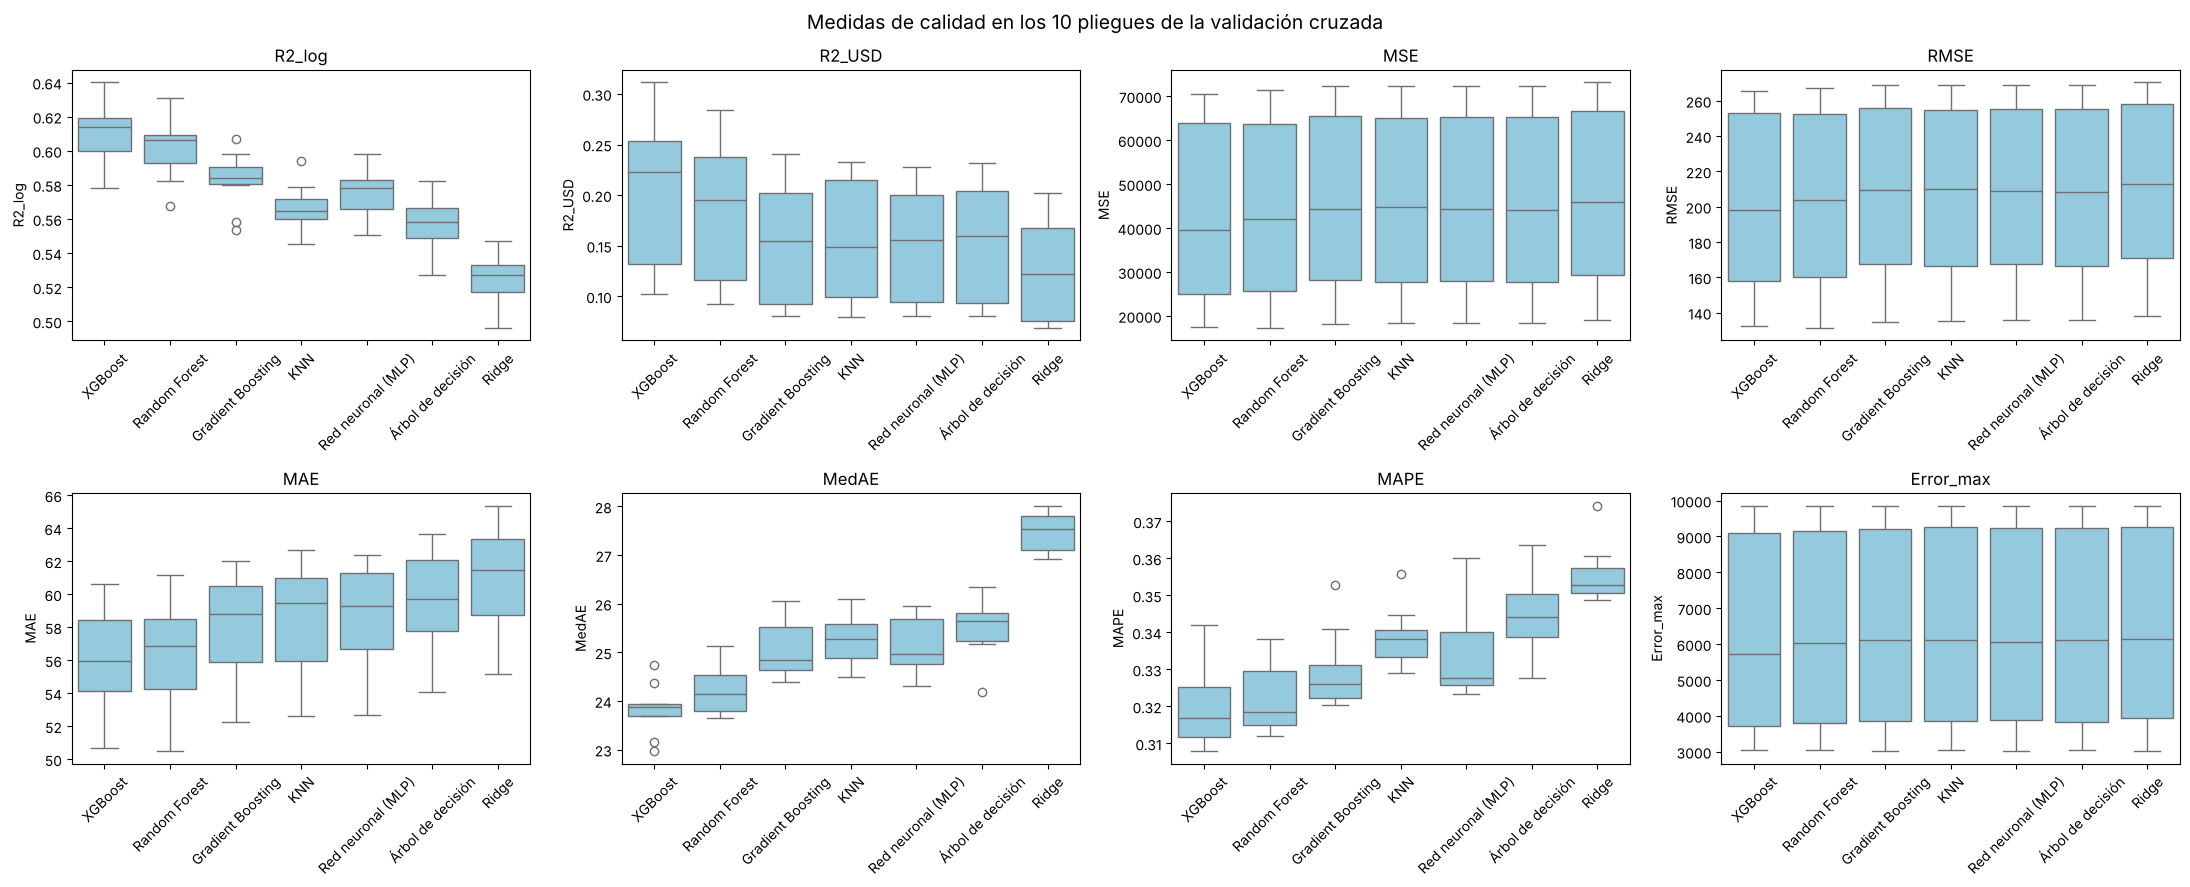

In [13]:
medidas = ['R2_log', 'R2_USD', 'MSE', 'RMSE', 'MAE', 'MedAE', 'MAPE', 'Error_max']
fig, ejes = plt.subplots(2, 4, figsize=(22, 9))
for eje, medida in zip(ejes.ravel(), medidas):
    sns.boxplot(data=resultados_cv, x='modelo', y=medida, order=resumen.index, color='skyblue', ax=eje)
    eje.set_title(medida)
    eje.set_xlabel('')
    eje.tick_params(axis='x', rotation=45)
plt.suptitle('Medidas de calidad en los 10 pliegues de la validación cruzada', fontsize=14)
plt.tight_layout()
plt.show()

**Interpretación de las medidas de calidad (validación cruzada con el 70 %)**

* **R² en escala logarítmica (0.53 – 0.61):** el mejor modelo (XGBoost) explica cerca del 61 % de la variabilidad del logaritmo del precio. Es un valor razonable: el dataset no incluye variables que influyen mucho en el precio, como el tamaño, el número de habitaciones o la calidad del alojamiento.
* **R² en dólares (0.12 – 0.20):** es mucho más bajo, pero no contradice lo anterior. En dólares, el R² está dominado por unos pocos alojamientos de miles de dólares (hasta 10 000 USD), que ningún modelo puede anticipar con estas variables: un solo error de 9 000 USD pesa más que miles de errores pequeños.
* **MSE (43 266 – 46 985 USD²):** promedio de los errores al cuadrado. Al estar en dólares al cuadrado no se interpreta directamente; su raíz es el RMSE. Como eleva cada error al cuadrado, está dominado por los pocos errores muy grandes.
* **MAE (55.9 – 61.1 USD):** en promedio, la predicción se aleja unos 56 USD del precio real con el mejor modelo.
* **RMSE (202 – 211 USD):** es unas 3.6 veces el MAE. Como eleva los errores al cuadrado, confirma que hay pocos errores muy grandes, los de los precios extremos.
* **MedAE (23.8 – 27.5 USD):** para la mitad de los alojamientos, el error es menor que unos 24 USD. Es la medida que mejor describe el error en un alojamiento típico.
* **MAPE (0.319 – 0.355, es decir, 31.9 % – 35.5 %):** en promedio, el error equivale a cerca de un tercio del precio.
* **Error máximo (6 234 – 6 414 USD, promedio de los 10 pliegues):** en cada pliegue, el peor error corresponde a un alojamiento de miles de dólares que el modelo predice como uno normal. Es muy parecido en los 7 modelos porque ninguno puede anticipar esos precios extremos con las variables disponibles.

**Comparación:** XGBoost y Random Forest son los mejores en las 8 medidas. Les siguen Gradient Boosting, KNN y la red neuronal con valores muy parecidos entre sí. La regresión Ridge es la peor en todas, lo que indica que la relación entre las variables y el precio no es lineal. En los diagramas de caja, la variación entre pliegues (sobre todo en MSE, RMSE, error máximo y R² en dólares, que dependen de en qué pliegue caen los precios extremos) es comparable a las diferencias entre modelos. Por eso hace falta una prueba estadística para decidir si esas diferencias son reales.

# 7. Selección de los 3 mejores modelos: ANOVA y Tukey (g)

Se compara el **MAE de los 10 pliegues** de los 7 modelos. Se usa el MAE porque está en dólares, es fácil de interpretar y no está dominado por unos pocos precios extremos, como sí ocurre con el RMSE y el R² en dólares.

* **ANOVA de un factor**: contrasta la hipótesis nula de que los 7 modelos tienen el mismo MAE medio.
  * H₀: μ₁ = μ₂ = … = μ₇
  * H₁: al menos un modelo tiene un MAE medio distinto.
* **Prueba de Tukey (HSD)**: si el ANOVA es significativo, compara los modelos por pares para saber **cuáles** difieren entre sí, controlando el error por comparaciones múltiples.

Nivel de significancia: α = 0.05.

In [14]:
# MAE de los 10 pliegues de cada modelo
mae = {}
for nombre in modelos:
    mae[nombre] = resultados_cv[resultados_cv['modelo'] == nombre]['MAE']

F, p_valor = f_oneway(mae['Ridge'], mae['KNN'], mae['Árbol de decisión'], mae['Red neuronal (MLP)'],
                      mae['Random Forest'], mae['Gradient Boosting'], mae['XGBoost'])
print('ANOVA: F =', round(F, 2), ' p-valor =', round(p_valor, 4))
if p_valor < 0.05:
    print('Se rechaza H0: hay diferencias significativas entre los modelos.')
else:
    print('No se rechaza H0: no hay diferencias significativas entre los modelos.')

ANOVA: F = 3.19  p-valor = 0.0086
Se rechaza H0: hay diferencias significativas entre los modelos.


In [15]:
tukey = pairwise_tukeyhsd(endog=resultados_cv['MAE'], groups=resultados_cv['modelo'], alpha=0.05)
print(tukey)

            Multiple Comparison of Means - Tukey HSD, FWER=0.05             
      group1             group2       meandiff p-adj   lower   upper  reject
----------------------------------------------------------------------------
 Gradient Boosting                KNN   0.4482 0.9999 -3.8571  4.7535  False
 Gradient Boosting      Random Forest  -1.8037 0.8602  -6.109  2.5015  False
 Gradient Boosting Red neuronal (MLP)   0.5694 0.9996 -3.7359  4.8747  False
 Gradient Boosting              Ridge   2.9381 0.3779 -1.3672  7.2434  False
 Gradient Boosting            XGBoost  -2.1796 0.7187 -6.4849  2.1257  False
 Gradient Boosting  Árbol de decisión   1.4986 0.9372 -2.8067  5.8039  False
               KNN      Random Forest  -2.2519 0.6871 -6.5572  2.0534  False
               KNN Red neuronal (MLP)   0.1212    1.0  -4.184  4.4265  False
               KNN              Ridge   2.4899 0.5784 -1.8154  6.7952  False
               KNN            XGBoost  -2.6278 0.5145 -6.9331  1.6775  False

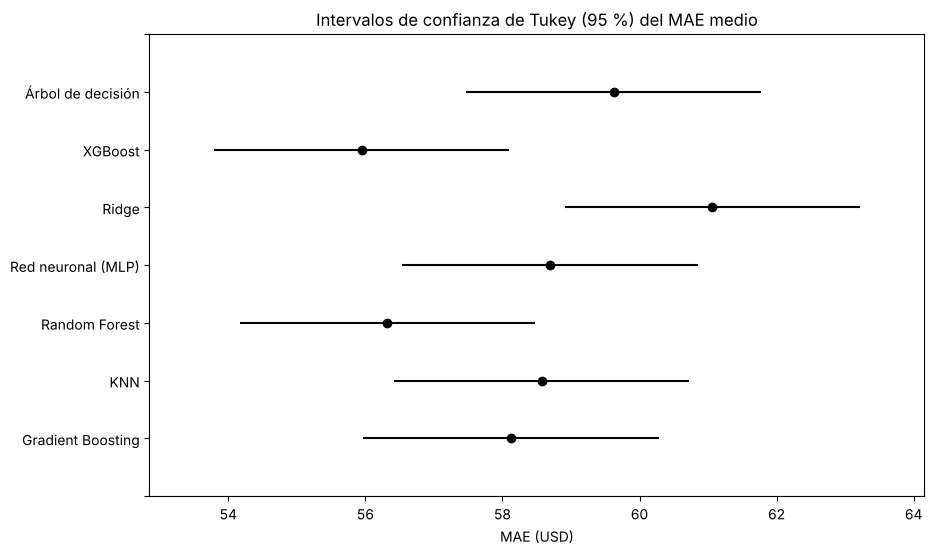

MAE medio por modelo:
modelo
XGBoost               55.94
Random Forest         56.32
Gradient Boosting     58.12
KNN                   58.57
Red neuronal (MLP)    58.69
Árbol de decisión     59.62
Ridge                 61.06
Name: MAE, dtype: float64

Modelos seleccionados: ['XGBoost', 'Random Forest', 'Gradient Boosting']


In [16]:
tukey.plot_simultaneous(xlabel='MAE (USD)')
plt.title('Intervalos de confianza de Tukey (95 %) del MAE medio')
plt.show()

print('MAE medio por modelo:')
print(resumen['MAE'].round(2))

mejores = list(resumen.index[:3])
print('\nModelos seleccionados:', mejores)

**Interpretación**

* **ANOVA:** F = 3.19 y p-valor = 0.0086 < 0.05. Se rechaza H₀: no todos los modelos tienen el mismo MAE medio.
* **Tukey:** de las 21 comparaciones por pares, solo 2 son significativas: **XGBoost vs. Ridge** (diferencia de 5.1 USD, p = 0.010) y **Random Forest vs. Ridge** (diferencia de 4.7 USD, p = 0.022). Las demás diferencias (de 0.1 a 3.7 USD) no son significativas: son pequeñas comparadas con la variación del MAE entre pliegues.

**Selección de los 3 mejores modelos**

1. **XGBoost** y 2. **Random Forest**: tienen el menor MAE medio y son los únicos significativamente mejores que el modelo lineal de referencia. Entre ellos no hay diferencia significativa (p = 1.0).
3. **Gradient Boosting**: su MAE medio (58.1 USD) es el tercero. Su diferencia con KNN (58.6) y la red neuronal (58.7) no es significativa, así que la prueba no permite separarlos. Se elige por tener el mejor MAE medio y el mejor R² logarítmico (0.583, frente a 0.574 de la red neuronal y 0.566 de KNN) y porque, al usar su configuración por defecto (100 árboles poco profundos), es el que más puede mejorar con la hiperparametrización.

Los tres modelos seleccionados son métodos de ensamble basados en árboles.

# 8. Hiperparametrización (h)

Cada uno de los 3 modelos seleccionados se optimiza con dos técnicas:

1. **GridSearchCV**: prueba **todas** las combinaciones de una rejilla de valores definida a mano.
2. **Optimización bayesiana (Optuna, algoritmo TPE)**: explora un espacio continuo de hiperparámetros; en cada intento usa los resultados anteriores para proponer combinaciones más prometedoras, por lo que necesita menos pruebas que una búsqueda exhaustiva.

Los 3 modelos seleccionados son XGBoost, Random Forest y Gradient Boosting. Ambas técnicas se evalúan con validación cruzada de 3 pliegues sobre el 70 % de entrenamiento, minimizando el MAE. Se usan 3 pliegues (en lugar de 10) para que el tiempo de ejecución sea razonable.

*Tiempo aproximado de esta sección en Colab: 15–25 minutos.*

In [17]:
kfold3 = KFold(n_splits=3, shuffle=True, random_state=42)

modelos_ajustados = {}   # modelo ajustado de cada combinación modelo - técnica
mae_cv = {}              # su MAE en validación cruzada

## 8.1 GridSearchCV

Dentro del pipeline, los hiperparámetros del modelo se nombran con el prefijo `regressor__modelo__`.

In [18]:
# XGBoost
parametros = {
    'regressor__modelo__n_estimators': [300, 600],
    'regressor__modelo__learning_rate': [0.03, 0.06],
    'regressor__modelo__max_depth': [6, 8],
    'regressor__modelo__subsample': [0.8],
}
grid = GridSearchCV(crear_pipeline(modelos['XGBoost']), parametros, scoring='neg_mean_absolute_error', cv=kfold3)
grid.fit(X_train, y_train)

print('Mejores parámetros:', grid.best_params_)
print('MAE (validación cruzada):', round(-grid.best_score_, 2))
modelos_ajustados['XGBoost - GridSearch'] = grid.best_estimator_
mae_cv['XGBoost - GridSearch'] = -grid.best_score_

Mejores parámetros: {'regressor__modelo__learning_rate': 0.03, 'regressor__modelo__max_depth': 8, 'regressor__modelo__n_estimators': 300, 'regressor__modelo__subsample': 0.8}
MAE (validación cruzada): 55.96


In [19]:
# Random Forest
parametros = {
    'regressor__modelo__max_depth': [None, 20],
    'regressor__modelo__min_samples_leaf': [3, 6],
    'regressor__modelo__max_features': [0.5],
}
grid = GridSearchCV(crear_pipeline(modelos['Random Forest']), parametros, scoring='neg_mean_absolute_error', cv=kfold3)
grid.fit(X_train, y_train)

print('Mejores parámetros:', grid.best_params_)
print('MAE (validación cruzada):', round(-grid.best_score_, 2))
modelos_ajustados['Random Forest - GridSearch'] = grid.best_estimator_
mae_cv['Random Forest - GridSearch'] = -grid.best_score_

Mejores parámetros: {'regressor__modelo__max_depth': 20, 'regressor__modelo__max_features': 0.5, 'regressor__modelo__min_samples_leaf': 3}
MAE (validación cruzada): 56.47


In [20]:
# Gradient Boosting
parametros = {
    'regressor__modelo__n_estimators': [200, 400],
    'regressor__modelo__learning_rate': [0.05, 0.1],
    'regressor__modelo__max_depth': [3, 5],
}
grid = GridSearchCV(crear_pipeline(modelos['Gradient Boosting']), parametros, scoring='neg_mean_absolute_error', cv=kfold3)
grid.fit(X_train, y_train)

print('Mejores parámetros:', grid.best_params_)
print('MAE (validación cruzada):', round(-grid.best_score_, 2))
modelos_ajustados['Gradient Boosting - GridSearch'] = grid.best_estimator_
mae_cv['Gradient Boosting - GridSearch'] = -grid.best_score_

Mejores parámetros: {'regressor__modelo__learning_rate': 0.05, 'regressor__modelo__max_depth': 5, 'regressor__modelo__n_estimators': 400}
MAE (validación cruzada): 56.84


## 8.2 Optimización bayesiana (Optuna)

En cada intento, Optuna propone una combinación de hiperparámetros, la evalúa con validación cruzada y usa los resultados anteriores para proponer la siguiente. Se hacen 20 intentos por modelo.

In [21]:
# XGBoost
def objetivo_xgb(trial):
    modelo = XGBRegressor(
        n_estimators=trial.suggest_int('n_estimators', 200, 1000),
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        max_depth=trial.suggest_int('max_depth', 3, 10),
        subsample=trial.suggest_float('subsample', 0.6, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.5, 1.0),
        min_child_weight=trial.suggest_int('min_child_weight', 1, 20),
        n_jobs=-1, random_state=42)
    scores = cross_val_score(crear_pipeline(modelo), X_train, y_train, cv=kfold3, scoring='neg_mean_absolute_error')
    return -scores.mean()

estudio = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
estudio.optimize(objetivo_xgb, n_trials=20)
print('Mejores parámetros:', estudio.best_params)
print('MAE (validación cruzada):', round(estudio.best_value, 2))

modelo = crear_pipeline(XGBRegressor(**estudio.best_params, n_jobs=-1, random_state=42))
modelo.fit(X_train, y_train)
modelos_ajustados['XGBoost - Bayesiana (Optuna)'] = modelo
mae_cv['XGBoost - Bayesiana (Optuna)'] = estudio.best_value

Mejores parámetros: {'n_estimators': 778, 'learning_rate': 0.015290780725853109, 'max_depth': 9, 'subsample': 0.6595642527846146, 'colsample_bytree': 0.7912892004380444, 'min_child_weight': 1}
MAE (validación cruzada): 55.76


In [22]:
# Random Forest
def objetivo_rf(trial):
    modelo = RandomForestRegressor(
        n_estimators=trial.suggest_int('n_estimators', 100, 250),
        max_depth=trial.suggest_int('max_depth', 10, 40),
        min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 10),
        max_features=trial.suggest_float('max_features', 0.3, 1.0),
        n_jobs=-1, random_state=42)
    scores = cross_val_score(crear_pipeline(modelo), X_train, y_train, cv=kfold3, scoring='neg_mean_absolute_error')
    return -scores.mean()

estudio = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
estudio.optimize(objetivo_rf, n_trials=20)
print('Mejores parámetros:', estudio.best_params)
print('MAE (validación cruzada):', round(estudio.best_value, 2))

modelo = crear_pipeline(RandomForestRegressor(**estudio.best_params, n_jobs=-1, random_state=42))
modelo.fit(X_train, y_train)
modelos_ajustados['Random Forest - Bayesiana (Optuna)'] = modelo
mae_cv['Random Forest - Bayesiana (Optuna)'] = estudio.best_value

Mejores parámetros: {'n_estimators': 199, 'max_depth': 18, 'min_samples_leaf': 1, 'max_features': 0.3411518468047765}
MAE (validación cruzada): 56.21


In [23]:
# Gradient Boosting
def objetivo_gb(trial):
    modelo = GradientBoostingRegressor(
        n_estimators=trial.suggest_int('n_estimators', 100, 500),
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        max_depth=trial.suggest_int('max_depth', 2, 6),
        subsample=trial.suggest_float('subsample', 0.6, 1.0),
        random_state=42)
    scores = cross_val_score(crear_pipeline(modelo), X_train, y_train, cv=kfold3, scoring='neg_mean_absolute_error')
    return -scores.mean()

estudio = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
estudio.optimize(objetivo_gb, n_trials=20)
print('Mejores parámetros:', estudio.best_params)
print('MAE (validación cruzada):', round(estudio.best_value, 2))

modelo = crear_pipeline(GradientBoostingRegressor(**estudio.best_params, random_state=42))
modelo.fit(X_train, y_train)
modelos_ajustados['Gradient Boosting - Bayesiana (Optuna)'] = modelo
mae_cv['Gradient Boosting - Bayesiana (Optuna)'] = estudio.best_value

Mejores parámetros: {'n_estimators': 280, 'learning_rate': 0.047850344249420876, 'max_depth': 6, 'subsample': 0.8574227408309127}
MAE (validación cruzada): 56.56


In [24]:
# Comparación de las dos técnicas (MAE en validación cruzada)
tabla_ajuste = pd.DataFrame({'MAE validación cruzada (USD)': mae_cv}).sort_values('MAE validación cruzada (USD)')
tabla_ajuste.round(2)

,MAE validación cruzada (USD)
XGBoost - Bayesiana (Optuna),55.76
XGBoost - GridSearch,55.96
Random Forest - Bayesiana (Optuna),56.21
Random Forest - GridSearch,56.47
Gradient Boosting - Bayesiana (Optuna),56.56
Gradient Boosting - GridSearch,56.84


**Interpretación**

* **La optimización bayesiana superó a GridSearch en los 3 modelos** (XGBoost: 55.77 vs. 55.96 USD; Random Forest: 56.21 vs. 56.47; Gradient Boosting: 56.56 vs. 56.84). GridSearch solo prueba las 4–8 combinaciones fijas de la rejilla. Optuna explora valores continuos y concentra los 20 intentos en las zonas más prometedoras.
* **Gradient Boosting es el que más mejoró** (de 58.1 a 56.6 USD). Con 100 árboles de profundidad 3 estaba infraajustado; con más árboles y más profundidad alcanza casi a Random Forest. XGBoost y Random Forest mejoraron menos de 0.6 USD porque su configuración inicial ya era buena.
* El MAE sin ajustar se calculó con 10 pliegues y el ajustado con 3, así que las diferencias pequeñas son orientativas.
* **Mejor modelo: XGBoost optimizado con Optuna** (MAE CV = 55.77 USD): 778 árboles, tasa de aprendizaje 0.015 y profundidad 9. Es una combinación de muchos árboles con aprendizaje lento, que suele generalizar bien.

# 9. Evaluación con el 30 % de prueba

Los 6 modelos ajustados (3 modelos × 2 técnicas) se evalúan con el conjunto de prueba con las mismas 8 medidas, que no se ha usado hasta ahora. El **mejor modelo** se elige por el menor MAE en validación cruzada (sección 8); la prueba confirma que el resultado se mantiene con datos nuevos y que no hay sobreajuste.

In [25]:
filas = []
for nombre, modelo in modelos_ajustados.items():
    medidas = calcular_medidas(y_test, modelo.predict(X_test))
    medidas['modelo'] = nombre
    medidas['MAE_val_cruzada'] = mae_cv[nombre]
    filas.append(medidas)

tabla_test = pd.DataFrame(filas).set_index('modelo').sort_values('MAE_val_cruzada')
tabla_test.round(3)

,R2_log,R2_USD,MSE,RMSE,MAE,MedAE,MAPE,Error_max,MAE_val_cruzada
modelo,,,,,,,,,
XGBoost - Bayesiana (Optuna),0.621,0.135,60244.812,245.448,56.921,22.971,0.310,9948.718,55.765
XGBoost - GridSearch,0.617,0.133,60382.344,245.728,57.173,23.286,0.312,9952.897,55.963
Random Forest - Bayesiana (Optuna),0.613,0.126,60908.884,246.797,57.381,23.529,0.312,9951.565,56.209
Random Forest - GridSearch,0.610,0.116,61583.403,248.160,57.675,23.834,0.314,9950.778,56.469
Gradient Boosting - Bayesiana (Optuna),0.612,0.126,60867.716,246.714,57.707,23.655,0.315,9944.025,56.556
Gradient Boosting - GridSearch,0.606,0.119,61347.893,247.685,58.069,23.701,0.317,9946.986,56.837


Mejor modelo: XGBoost - Bayesiana (Optuna)


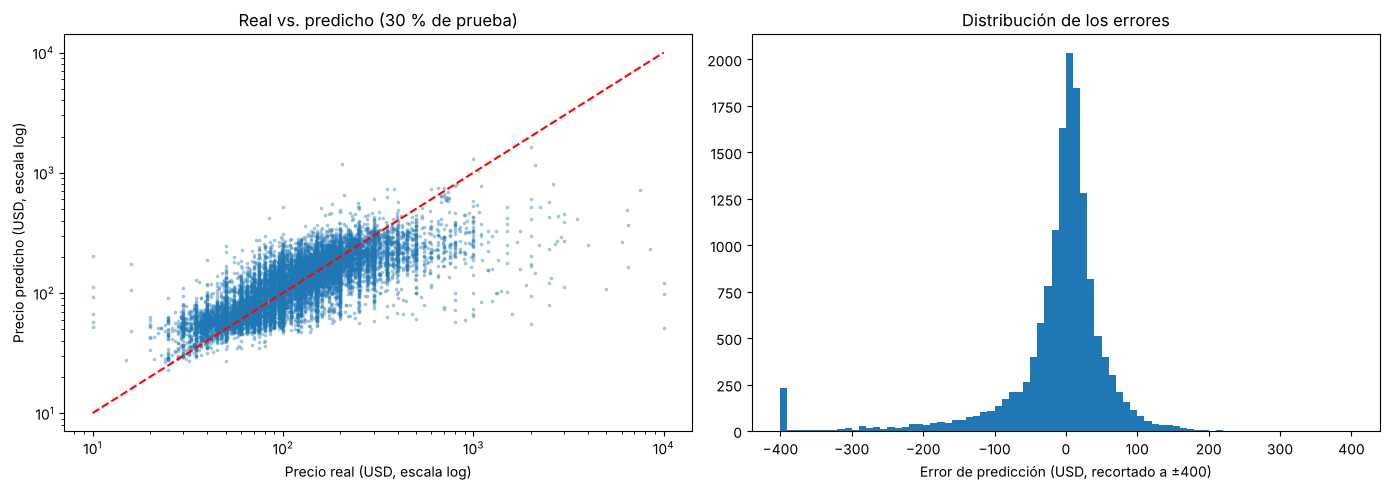

In [26]:
# El mejor modelo es el de menor MAE en validación cruzada
mejor = tabla_test.index[0]
modelo_final = modelos_ajustados[mejor]
print('Mejor modelo:', mejor)

pred_test = modelo_final.predict(X_test)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(y_test, pred_test, s=3, alpha=0.3)
ax[0].plot([10, 10000], [10, 10000], 'r--')
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_xlabel('Precio real (USD, escala log)')
ax[0].set_ylabel('Precio predicho (USD, escala log)')
ax[0].set_title('Real vs. predicho (30 % de prueba)')
ax[1].hist((pred_test - y_test).clip(-400, 400), bins=80)
ax[1].set_xlabel('Error de predicción (USD, recortado a ±400)')
ax[1].set_title('Distribución de los errores')
plt.tight_layout()
plt.show()

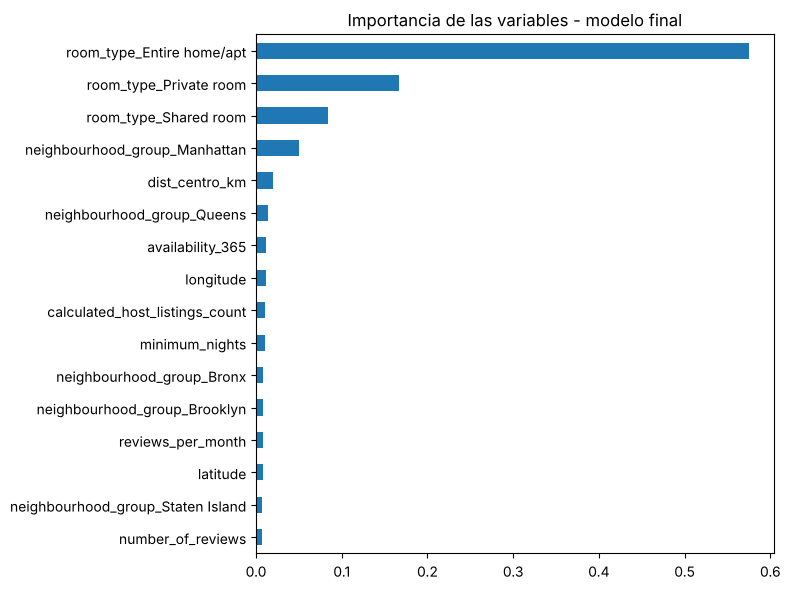

In [27]:
# Importancia de las variables del modelo final
modelo_interno = modelo_final.regressor_.named_steps['modelo']
nombres = modelo_final.regressor_.named_steps['preprocesamiento'].get_feature_names_out()

importancia = pd.Series(modelo_interno.feature_importances_, index=nombres).sort_values()
importancia.plot.barh(figsize=(8, 6))
plt.title('Importancia de las variables - modelo final')
plt.tight_layout()
plt.show()

**Interpretación de la evaluación con el 30 % de prueba**

* **El orden de los modelos se mantiene:** XGBoost con Optuna es el mejor en todas las medidas, salvo el error máximo, que es prácticamente igual en los 6 modelos (≈ 9 950 USD).
* **No hay sobreajuste:** el MAE en prueba (56.9 USD) es casi igual al de validación cruzada (55.8 USD), y el R² logarítmico también (0.62 frente a 0.61). El modelo generaliza bien.
* **R² en dólares (0.135), MSE (60 245 USD²) y RMSE (245 USD)** son peores que en validación cruzada porque el conjunto de prueba contiene 10 alojamientos de 5 000 USD o más (incluido uno de 10 000 USD), que dominan las medidas basadas en errores al cuadrado. Las medidas robustas (MAE, MedAE, MAPE y R² logarítmico) se mantienen estables.
* **Error máximo (9 949 USD):** corresponde al alojamiento de 10 000 USD por noche del conjunto de prueba, al que el modelo asigna un precio normal (unos 51 USD). Es un caso aislado: el **96 % de las predicciones tiene un error menor de 200 USD**.
* **En la práctica:** para un alojamiento típico, el modelo se equivoca unos **23 USD** (MedAE), con un error relativo medio del **31 %** (MAPE). Sirve como precio de referencia para alojamientos comunes, pero no para el segmento de lujo, cuyos precios dependen de variables que el dataset no incluye.
* **Gráfico real vs. predicho:** los puntos siguen la diagonal, pero el modelo subestima los alojamientos muy caros y sobreestima los muy baratos. Es lo esperable cuando faltan variables que expliquen los extremos.
* **Importancia de las variables:** el tipo de alojamiento es, con diferencia, lo más importante (casa o apartamento entero ≈ 0.58), seguido de estar en Manhattan (≈ 0.05) y de **`dist_centro_km`**, la variable numérica más importante. Esto confirma que crear la distancia al centro en la ingeniería de características fue útil para representar la ubicación.

# 10. Pipeline final para despliegue (i)

El modelo final se almacena en un **pipeline** (`modelo_final`) que contiene, en orden, todas las operaciones necesarias para pasar de un registro "crudo" al precio en dólares:

| Paso | Clase | Operación |
|---|---|---|
| 1. Preparación de datos | `FunctionTransformer(preparar_datos)` | Selecciona las 9 variables del modelo (descarta `id`, `name`, `host_id`, `host_name`, `neighbourhood`, `last_review`), rellena `reviews_per_month` vacío con 0 y aplica las reglas de calidad (`minimum_nights` entre 1 y 365, `availability_365` entre 0 y 365). |
| 2. Ingeniería de características | `FunctionTransformer(crear_variables)` | Crea `dist_centro_km` y aplica `log(1 + x)` a los conteos sesgados. |
| 3. Transformación | `ColumnTransformer` | Estandariza las variables numéricas y codifica con one-hot las categóricas. |
| 4. Modelo | `XGBRegressor` | Modelo optimizado. |
| 5. Transformación del objetivo | `TransformedTargetRegressor` | Entrena con `log(1 + price)` y devuelve la predicción en dólares. |

El pipeline se guarda con `joblib` en `modelo_final_airbnb.pkl`. Para cargarlo se necesita el archivo `features.py`, que contiene las funciones de los pasos 1 y 2.

In [28]:
# Estructura del pipeline final
modelo_final

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.","Pipeline(step...=None, ...))])"
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['neighbourhood_group','latitude','longitude',...,'reviews_per_month', 'calculated_host_listings_count','availability_365']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,9
regressor_ regressor_: objectFitted regressor.,Pipeline,"Pipeline(step...=None, ...))])"
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacion', ...), ('ingenieria', ...), ...]"


In [29]:
joblib.dump(modelo_final, 'modelo_final_airbnb.pkl')
print('Modelo guardado en modelo_final_airbnb.pkl')

Modelo guardado en modelo_final_airbnb.pkl


## Comprobación del pipeline guardado

Se verifica que el pipeline guardado:

1. **Se carga correctamente** y da exactamente las mismas predicciones que el modelo en memoria sobre el 30 % de prueba.
2. **Aplica la preparación de datos por sí mismo**: recibe registros con el formato del archivo original `AB_NYC_2019.csv` (16 columnas, con identificadores, nombres, `reviews_per_month` vacío y valores fuera de las reglas de calidad) y devuelve el precio sin necesidad de preparar los datos a mano.

In [30]:
modelo_cargado = joblib.load('modelo_final_airbnb.pkl')

# 1. El modelo cargado da las mismas predicciones que el modelo en memoria
pred_memoria = modelo_final.predict(X_test)
pred_cargado = modelo_cargado.predict(X_test)
print('¿Predicciones idénticas en el 30 % de prueba?:', np.allclose(pred_memoria, pred_cargado))
print('MAE del modelo cargado:', round(mean_absolute_error(y_test, pred_cargado), 2), 'USD')

¿Predicciones idénticas en el 30 % de prueba?: True
MAE del modelo cargado: 56.92 USD


In [31]:
# 2. Registros nuevos con el formato del archivo ORIGINAL (sin preparar)
nuevos = pd.DataFrame({
    'id': [99990001, 99990002, 99990003],
    'name': ['Loft cerca de Times Square', 'Habitación en Brooklyn', 'Estudio en Queens'],
    'host_id': [123, 456, 789],
    'host_name': ['Ana', 'Luis', 'Sara'],
    'neighbourhood_group': ['Manhattan', 'Brooklyn', 'Queens'],
    'neighbourhood': ['Midtown', 'Williamsburg', 'Astoria'],
    'latitude': [40.7549, 40.7081, 40.7644],
    'longitude': [-73.9840, -73.9571, -73.9235],
    'room_type': ['Entire home/apt', 'Private room', 'Entire home/apt'],
    'minimum_nights': [2, 3, 1000],              # 1000 está fuera de la regla de calidad
    'number_of_reviews': [25, 0, 4],
    'last_review': ['2019-06-30', None, '2019-05-01'],
    'reviews_per_month': [1.2, None, 0.3],       # vacío: anuncio sin reseñas
    'calculated_host_listings_count': [1, 1, 2],
    'availability_365': [150, 300, 365],
})

print('Datos después del paso de preparación:')
display(preparar_datos(nuevos))

nuevos['precio_estimado_USD'] = modelo_cargado.predict(nuevos).round(0)
nuevos[['name', 'neighbourhood_group', 'room_type', 'precio_estimado_USD']]

Datos después del paso de preparación:


,neighbourhood_group,latitude,longitude,room_type,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Manhattan,40.7549,-73.9840,Entire home/apt,2,25,1.2,1,150
1,Brooklyn,40.7081,-73.9571,Private room,3,0,0.0,1,300
2,Queens,40.7644,-73.9235,Entire home/apt,365,4,0.3,2,365


,name,neighbourhood_group,room_type,precio_estimado_USD
0,Loft cerca de Times Square,Manhattan,Entire home/apt,295.0
1,Habitación en Brooklyn,Brooklyn,Private room,100.0
2,Estudio en Queens,Queens,Entire home/apt,233.0


El pipeline guardado se carga, reproduce exactamente las predicciones del modelo final y prepara por sí mismo los registros nuevos: descarta las columnas que no usa, rellena con 0 las reseñas por mes vacías y ajusta los valores fuera de las reglas de calidad. Por lo tanto, **el modelo final queda almacenado en un pipeline con todas las operaciones de preparación de los datos**, listo para el despliegue.

# 11. Descarga del modelo final

Se descarga `modelo_final_airbnb.pkl` para usarlo en el notebook de despliegue (**Despliegue_Airbnb_NYC**), que vuelve a crear el archivo `features.py` con el mismo contenido.

In [ ]:
from google.colab import files
files.download('modelo_final_airbnb.pkl')